In [4]:
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent
elif (project_root / "notebooks").is_dir():
    pass
elif (project_root.parent / "notebooks").is_dir():
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"

print("Processed folder:", processed_dir)
print("\nCSV files available:")

if processed_dir.exists():
    for file in sorted(processed_dir.glob("*.csv")):
        print(file.name)
else:
    print("Processed folder does not exist.")

Processed folder: c:\Users\INDIA\BrandVisibility\data\processed

CSV files available:
brand_api_cleaned.csv
brand_dirty_cleaned.csv
brand_visibility_combined.csv
brand_visibility_features.csv


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate project folders
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
elif (current_dir / "notebooks").is_dir():
    project_root = current_dir
elif (current_dir.parent / "notebooks").is_dir():
    project_root = current_dir.parent
else:
    project_root = current_dir

processed_dir = project_root / "data" / "processed"
combined_path = processed_dir / "brand_visibility_combined.csv"

if not combined_path.exists():
    raise FileNotFoundError(f"Combined dataset not found: {combined_path}")

# Reload the combined dataset
df_features = pd.read_csv(combined_path)

# Extract brands from product titles
known_brands = [
    "Apple", "Samsung", "HP", "Dell", "Lenovo",
    "Sony", "LG", "Boat", "Nike", "Adidas", "Puma",
    "Realme", "OnePlus", "Xiaomi", "Redmi", "Asus",
    "Acer", "JBL", "Canon", "Whirlpool", "Bosch",
    "Philips", "Havells", "Prestige"
]

def extract_brand(title):
    if pd.isna(title):
        return "Unknown"

    title = str(title).strip()

    for brand in sorted(known_brands, key=len, reverse=True):
        if title.lower().startswith(brand.lower()):
            return brand

    return "Unknown"

df_features["brand"] = df_features["title"].apply(extract_brand)

# Create price categories
def categorize_price(price):
    if pd.isna(price) or price <= 0:
        return "Unknown"
    elif price < 1000:
        return "Budget"
    elif price < 5000:
        return "Mid-Range"
    elif price < 20000:
        return "Premium"
    return "High-End"

df_features["price_range"] = df_features["price"].apply(categorize_price)

# Calculate a simple position-based visibility score
df_features["visibility_score"] = np.where(
    df_features["position"].notna() & (df_features["position"] >= 1),
    (100 - ((df_features["position"] - 1) / 39 * 100)).clip(0, 100),
    np.nan
)

# Save the output
processed_dir.mkdir(parents=True, exist_ok=True)
features_path = processed_dir / "brand_visibility_features.csv"

df_features.to_csv(features_path, index=False, encoding="utf-8-sig")

print("Feature-engineered dataset saved successfully!")
print("Location:", features_path)
print("Shape:", df_features.shape)

Feature-engineered dataset saved successfully!
Location: c:\Users\INDIA\BrandVisibility\data\processed\brand_visibility_features.csv
Shape: (1360, 14)


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
elif (current_dir / "data" / "processed").exists():
    project_root = current_dir
elif (current_dir.parent / "data" / "processed").exists():
    project_root = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot identify the project folder. Check Path.cwd()."
    )

# Load the feature-engineered dataset
features_path = (
    project_root / "data" / "processed"
    / "brand_visibility_features.csv"
)

if not features_path.exists():
    raise FileNotFoundError(
        f"File not found: {features_path}. "
        "Create it in 02_data_cleaning.ipynb first."
    )

df_eda = pd.read_csv(features_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df_eda.shape)
print("Columns:", df_eda.columns.tolist())

display(df_eda.head())

Dataset loaded successfully!
Dataset shape: (1360, 14)
Columns: ['keyword', 'title', 'price', 'rating', 'reviews', 'platform', 'delivery', 'position', 'product_id', 'product_link', 'data_source', 'brand', 'price_range', 'visibility_score']


,keyword,title,price,rating,reviews,platform,delivery,position,product_id,product_link,data_source,brand,price_range,visibility_score
0,office chair ergonomic,HP office chair ergonomic Model 603,36225.0,3.7,3241.0,croma,2 days,NaN,,NaN,provided_dataset,HP,High-End,NaN
1,microwave oven convection,Samsung microwave oven convection Model 524,NaN,4.7,1294.0,amazon,free delivery,NaN,,NaN,provided_dataset,Samsung,Unknown,NaN
2,power bank fast charging,Samsung power bank fast charging Model 402,NaN,NaN,3070.0,croma,free delivery,NaN,,NaN,provided_dataset,Samsung,Unknown,NaN
3,microwave oven convection,Dell microwave oven convection Model 877,2507.0,4.7,3446.0,flipkart,free delivery,NaN,,NaN,provided_dataset,Dell,Mid-Range,NaN
4,men running shoes,Dell men running shoes Model 536,2176.0,3.8,2031.0,croma,5 days,NaN,,NaN,provided_dataset,Dell,Mid-Range,NaN


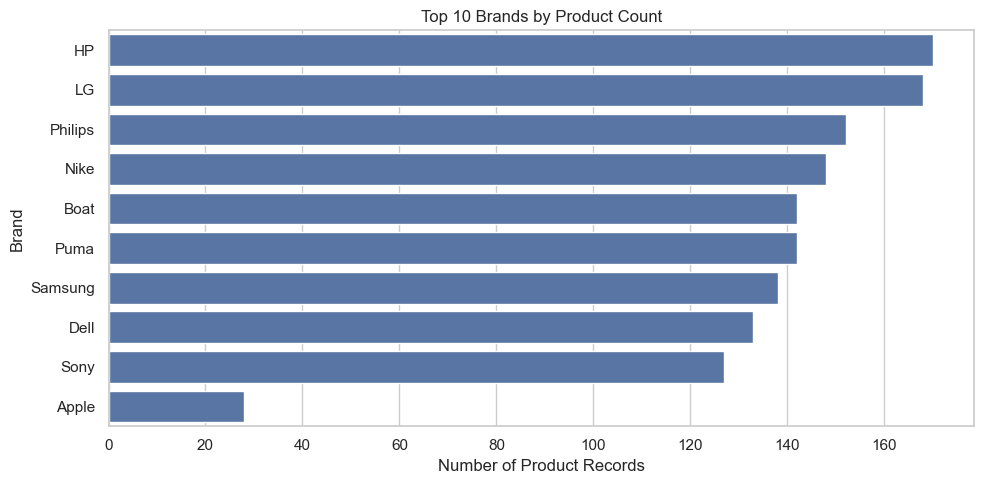

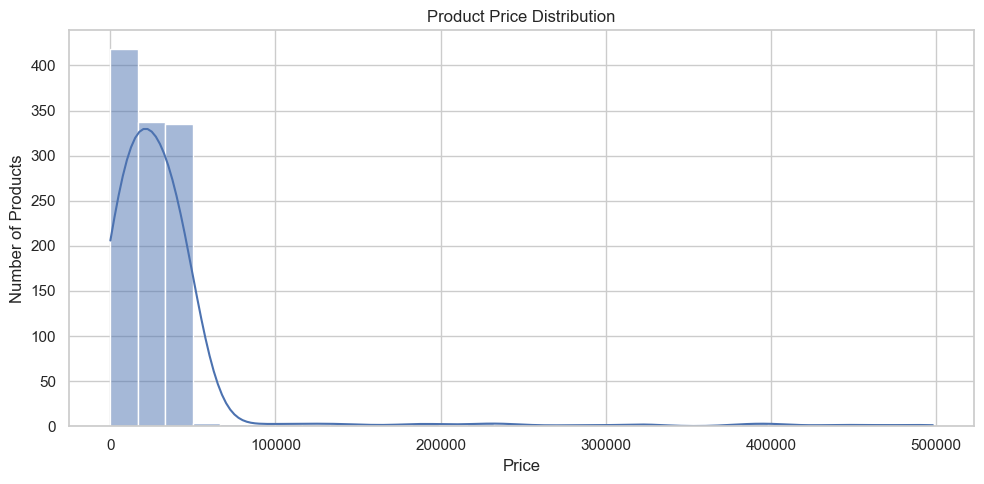

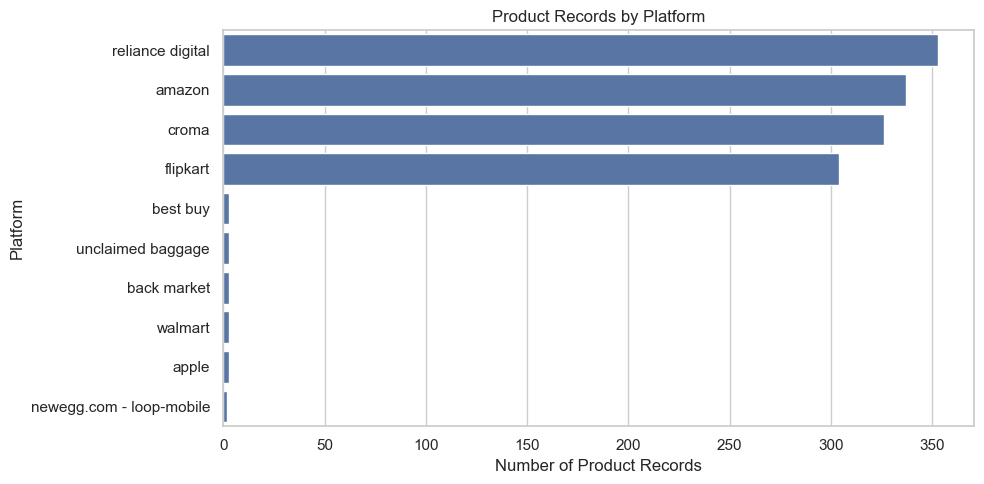

In [6]:
# Configure chart appearance
sns.set_theme(style="whitegrid")

# Chart 1: Top 10 brands by number of product records
brand_counts = (
    df_eda.loc[df_eda["brand"] != "Unknown", "brand"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=brand_counts.values, y=brand_counts.index)
plt.title("Top 10 Brands by Product Count")
plt.xlabel("Number of Product Records")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


# Chart 2: Product price distribution
valid_prices = df_eda.loc[
    df_eda["price"].notna() & (df_eda["price"] > 0),
    "price"
]

plt.figure(figsize=(10, 5))
sns.histplot(valid_prices, bins=30, kde=True)
plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


# Chart 3: Product records by platform
platform_counts = (
    df_eda["platform"]
    .fillna("Unknown")
    .str.lower()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=platform_counts.values, y=platform_counts.index)
plt.title("Product Records by Platform")
plt.xlabel("Number of Product Records")
plt.ylabel("Platform")
plt.tight_layout()
plt.show()

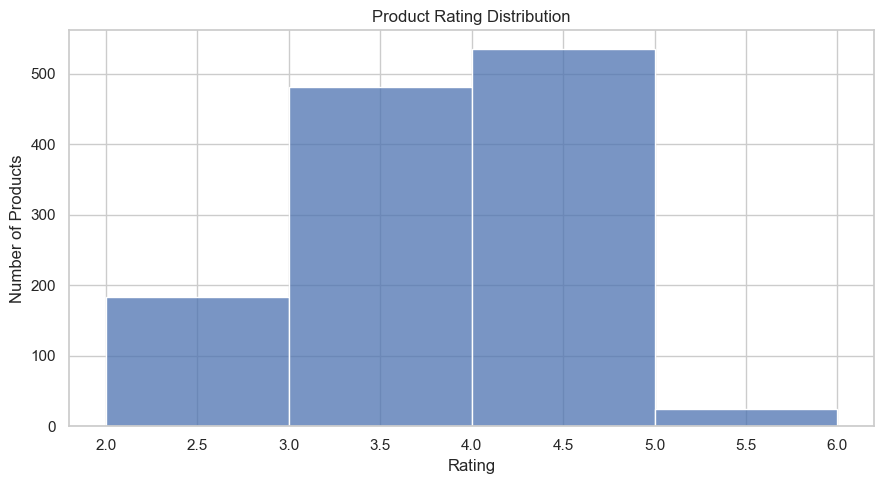

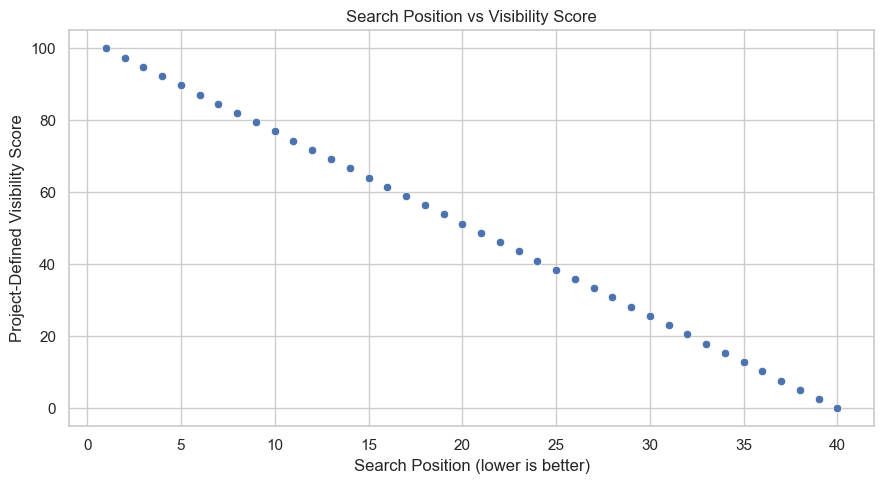

In [7]:
# Chart 4: Rating distribution
valid_ratings = df_eda.loc[
    df_eda["rating"].between(0, 5),
    "rating"
].dropna()

plt.figure(figsize=(9, 5))
sns.histplot(valid_ratings, bins=10, discrete=True)
plt.title("Product Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


# Chart 5: Search visibility by position
ranked_products = df_eda.loc[
    df_eda["position"].notna()
    & df_eda["visibility_score"].notna()
].copy()

if not ranked_products.empty:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=ranked_products,
        x="position",
        y="visibility_score"
    )
    plt.title("Search Position vs Visibility Score")
    plt.xlabel("Search Position (lower is better)")
    plt.ylabel("Project-Defined Visibility Score")
    plt.tight_layout()
    plt.show()
else:
    print("No search ranking data available for this chart.")

In [8]:
# Exclude unknown brands from the brand-level comparison
known_brand_data = df_eda[df_eda["brand"] != "Unknown"].copy()

brand_summary = (
    known_brand_data
    .groupby("brand")
    .agg(
        product_count=("title", "count"),
        average_price=("price", "mean"),
        average_rating=("rating", "mean"),
        total_reviews=("reviews", "sum")
    )
    .sort_values("product_count", ascending=False)
    .round(2)
)

print("BRAND PERFORMANCE SUMMARY")
display(brand_summary.head(15))

BRAND PERFORMANCE SUMMARY


,product_count,average_price,average_rating,total_reviews
brand,,,,
HP,170,33299.64,3.87,382486.0
LG,168,28836.18,3.74,378540.0
Philips,152,30129.80,3.81,380515.0
Nike,148,35075.29,3.76,364353.0
Boat,142,44399.65,3.83,350775.0
Puma,142,38515.66,3.82,331651.0
Samsung,138,26495.65,3.65,345245.0
Dell,133,39872.13,3.78,311213.0
Sony,127,33083.43,3.87,286571.0


In [9]:
platform_summary = (
    df_eda
    .groupby("platform", dropna=False)
    .agg(
        product_count=("title", "count"),
        average_price=("price", "mean"),
        average_rating=("rating", "mean"),
        total_reviews=("reviews", "sum"),
        ranked_products=("position", "count"),
        average_visibility=("visibility_score", "mean")
    )
    .sort_values("product_count", ascending=False)
    .round(2)
)

print("PLATFORM PERFORMANCE SUMMARY")
display(platform_summary)

PLATFORM PERFORMANCE SUMMARY


,product_count,average_price,average_rating,total_reviews,ranked_products,average_visibility
platform,,,,,,
reliance digital,353,37372.29,3.73,844806.0,0,NaN
amazon,337,37881.87,3.80,790421.0,0,NaN
croma,326,31341.42,3.85,776489.0,0,NaN
flipkart,304,30774.17,3.79,719633.0,0,NaN
back market,3,900.78,4.13,1842.0,3,45.30
best buy,3,703.32,4.37,302.0,3,78.63
walmart,3,432.75,4.03,2374.0,3,62.39
unclaimed baggage,3,491.66,NaN,0.0,3,20.51
apple,3,298.53,4.03,10053.0,3,88.03


In [10]:
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

brand_summary.to_csv(reports_dir / "brand_summary.csv")
platform_summary.to_csv(reports_dir / "platform_summary.csv")

print("Summary tables saved successfully!")
print("Folder:", reports_dir)
print("Files:")
print("- brand_summary.csv")
print("- platform_summary.csv")

Summary tables saved successfully!
Folder: c:\Users\INDIA\BrandVisibility\reports
Files:
- brand_summary.csv
- platform_summary.csv


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep only valid positive prices
valid_price_data = df_eda[
    df_eda["price"].notna() & (df_eda["price"] > 0)
].copy()

# Summarize price ranges
price_summary = (
    valid_price_data
    .groupby("price_range", dropna=False)
    .agg(
        product_count=("title", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        minimum_price=("price", "min"),
        maximum_price=("price", "max")
    )
    .round(2)
    .sort_values("average_price")
)

print("PRICE RANGE SUMMARY")
display(price_summary)

PRICE RANGE SUMMARY


,product_count,average_price,median_price,minimum_price,maximum_price
price_range,,,,,
Budget,47,600.70,609.2,20.25,987.95
Mid-Range,104,2879.10,2845.0,1010.00,4964.00
Premium,346,12377.26,12320.0,5007.00,19924.00
High-End,645,51753.71,36164.0,20041.00,498050.00


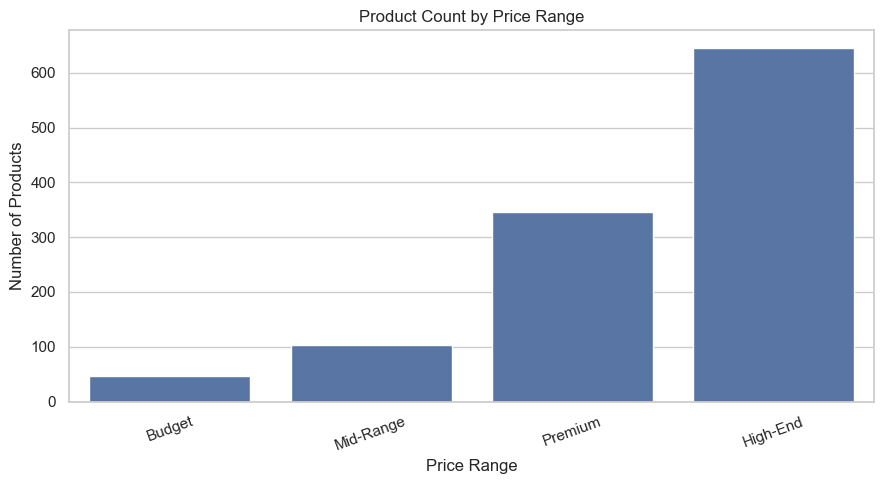

In [12]:
price_counts = (
    valid_price_data["price_range"]
    .value_counts()
    .reindex(["Budget", "Mid-Range", "Premium", "High-End"])
    .dropna()
)

plt.figure(figsize=(9, 5))
sns.barplot(x=price_counts.index, y=price_counts.values)
plt.title("Product Count by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Products")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [13]:
# Work with the combined feature dataset
discount_data = df_eda.copy()

if "extracted_old_price" in discount_data.columns:
    discount_data["old_price"] = pd.to_numeric(
        discount_data["extracted_old_price"],
        errors="coerce"
    )
else:
    discount_data["old_price"] = np.nan

# A valid discount requires an old price greater than the current price
valid_discount = (
    discount_data["price"].notna()
    & discount_data["old_price"].notna()
    & (discount_data["price"] > 0)
    & (discount_data["old_price"] > discount_data["price"])
)

discount_data["discount_percent"] = np.nan

discount_data.loc[valid_discount, "discount_percent"] = (
    (
        discount_data.loc[valid_discount, "old_price"]
        - discount_data.loc[valid_discount, "price"]
    )
    / discount_data.loc[valid_discount, "old_price"]
    * 100
)

print("Products with valid old prices:", discount_data["old_price"].notna().sum())
print("Products with calculable discounts:", discount_data["discount_percent"].notna().sum())

display(
    discount_data.loc[
        discount_data["discount_percent"].notna(),
        ["title", "price", "old_price", "discount_percent"]
    ].head(10).round(2)
)

Products with valid old prices: 0
Products with calculable discounts: 0


,title,price,old_price,discount_percent


In [14]:
discounts = discount_data["discount_percent"].dropna()

if not discounts.empty:
    plt.figure(figsize=(9, 5))
    sns.histplot(discounts, bins=10, kde=True)
    plt.title("Distribution of Product Discounts")
    plt.xlabel("Discount (%)")
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No valid discounts could be calculated. "
        "This can happen when the API results contain no valid old prices."
    )

No valid discounts could be calculated. This can happen when the API results contain no valid old prices.


In [15]:
# Check the old-price information in your combined dataset

print("Total products:", len(df_eda))

if "extracted_old_price" in df_eda.columns:
    old_prices = pd.to_numeric(
        df_eda["extracted_old_price"],
        errors="coerce"
    )

    current_prices = pd.to_numeric(
        df_eda["price"],
        errors="coerce"
    )

    print("Products with old prices:", old_prices.notna().sum())
    print("Products without old prices:", old_prices.isna().sum())

    valid_comparisons = (
        old_prices.notna()
        & current_prices.notna()
        & (old_prices > current_prices)
        & (current_prices > 0)
    )

    print("Products with valid discounts:", valid_comparisons.sum())

    print("\nExamples of available old prices:")
    display(
        df_eda.loc[
            old_prices.notna(),
            ["title", "price", "extracted_old_price"]
        ].head(10)
    )
else:
    print("The extracted_old_price column is not available.")

Total products: 1360
The extracted_old_price column is not available.


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np

features_path = (
    project_root
    / "data"
    / "processed"
    / "brand_visibility_features.csv"
)

# Reload the combined dataset, including old prices
combined_path = (
    project_root
    / "data"
    / "processed"
    / "brand_visibility_combined.csv"
)

df_eda = pd.read_csv(combined_path)

print("Total products:", len(df_eda))
print("Old-price column available:", "old_price" in df_eda.columns)

if "old_price" in df_eda.columns:
    print("Products with old prices:", df_eda["old_price"].notna().sum())

Total products: 1360
Old-price column available: False


In [17]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project folders
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
elif (current_dir / "data" / "processed").exists():
    project_root = current_dir
else:
    project_root = current_dir.parent

processed_dir = project_root / "data" / "processed"

# Load the combined dataset and cleaned API dataset
combined_path = processed_dir / "brand_visibility_combined.csv"
api_path = processed_dir / "brand_api_cleaned.csv"

df_combined = pd.read_csv(combined_path)
df_api_clean = pd.read_csv(api_path)

# Preserve the old price from the API data
if "extracted_old_price" in df_api_clean.columns:
    api_old_prices = pd.to_numeric(
        df_api_clean["extracted_old_price"],
        errors="coerce"
    )
else:
    api_old_prices = pd.Series(
        np.nan,
        index=df_api_clean.index
    )

# Initialize the column for all combined records
df_combined["old_price"] = np.nan

# API rows were appended after the dirty dataset rows
api_mask = df_combined["data_source"].eq("serpapi")

if api_mask.sum() != len(api_old_prices):
    raise ValueError(
        "The API row count does not match. "
        "Please check the combined dataset before updating."
    )

df_combined.loc[api_mask, "old_price"] = api_old_prices.to_numpy()

# Save the updated combined dataset
df_combined.to_csv(
    combined_path,
    index=False,
    encoding="utf-8-sig"
)

print("Combined dataset updated successfully!")
print("Total rows:", len(df_combined))
print("Old prices available:", df_combined["old_price"].notna().sum())
print("Saved to:", combined_path)

Combined dataset updated successfully!
Total rows: 1360
Old prices available: 5
Saved to: c:\Users\INDIA\BrandVisibility\data\processed\brand_visibility_combined.csv


In [18]:
from pathlib import Path
import pandas as pd
import numpy as np

features_path = (
    project_root
    / "data"
    / "processed"
    / "brand_visibility_features.csv"
)

# Reload the combined dataset, including old prices
combined_path = (
    project_root
    / "data"
    / "processed"
    / "brand_visibility_combined.csv"
)

df_eda = pd.read_csv(combined_path)

print("Total products:", len(df_eda))
print("Old-price column available:", "old_price" in df_eda.columns)

if "old_price" in df_eda.columns:
    print("Products with old prices:", df_eda["old_price"].notna().sum())

Total products: 1360
Old-price column available: True
Products with old prices: 5


In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
elif (current_dir / "data" / "processed").exists():
    project_root = current_dir
else:
    project_root = current_dir.parent

features_path = (
    project_root / "data" / "processed"
    / "brand_visibility_features.csv"
)

df_eda = pd.read_csv(features_path)

print("Updated EDA dataset loaded!")
print("Shape:", df_eda.shape)
print("Available columns:", df_eda.columns.tolist())

Updated EDA dataset loaded!
Shape: (1360, 16)
Available columns: ['keyword', 'title', 'price', 'rating', 'reviews', 'platform', 'delivery', 'position', 'product_id', 'product_link', 'data_source', 'old_price', 'brand', 'price_range', 'visibility_score', 'discount_percent']


,product_count,average_price,median_price
brand,,,
HP,151,33299.64,26570.00
LG,141,28836.18,23503.00
Nike,126,35075.29,22684.00
Puma,125,38515.66,25806.00
Boat,122,44399.65,21921.50
Dell,117,39872.13,26693.00
Philips,112,30129.80,23769.50
Samsung,106,26495.65,20374.50
Sony,102,33083.43,25404.00


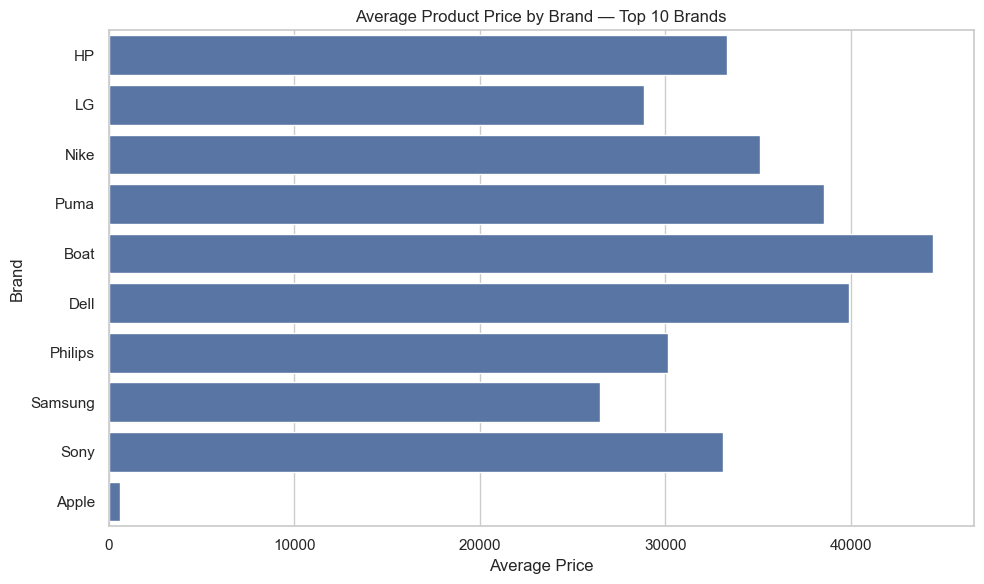

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Compare brands using products with valid prices
brand_price_data = df_eda[
    (df_eda["brand"] != "Unknown")
    & df_eda["price"].notna()
    & (df_eda["price"] > 0)
].copy()

brand_price_summary = (
    brand_price_data
    .groupby("brand")
    .agg(
        product_count=("title", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median")
    )
    .sort_values("product_count", ascending=False)
    .head(10)
    .round(2)
)

display(brand_price_summary)

# Visualize the average prices of the top brands
if not brand_price_summary.empty:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=brand_price_summary.reset_index(),
        x="average_price",
        y="brand"
    )
    plt.title("Average Product Price by Brand — Top 10 Brands")
    plt.xlabel("Average Price")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()
else:
    print("No products with recognized brands and valid prices.")

,product_count,rated_products,average_rating,average_price
platform,,,,
reliance digital,353,309,3.73,37372.29
amazon,337,300,3.80,37881.87
croma,326,309,3.85,31341.42
flipkart,304,271,3.79,30774.17
back market,3,3,4.13,900.78
best buy,3,3,4.37,703.32
walmart,3,3,4.03,432.75
unclaimed baggage,3,0,NaN,491.66
apple,3,3,4.03,298.53


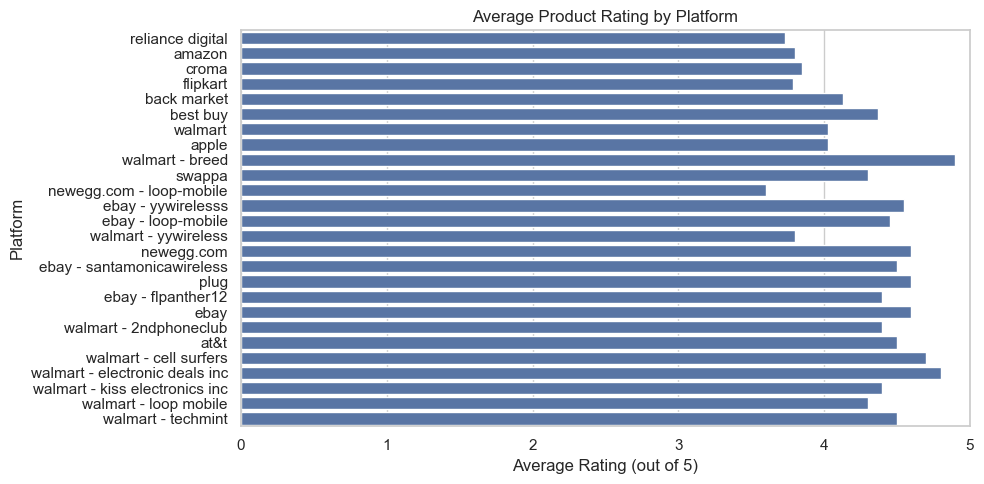

In [21]:
platform_rating_summary = (
    df_eda
    .groupby("platform", dropna=False)
    .agg(
        product_count=("title", "count"),
        rated_products=("rating", "count"),
        average_rating=("rating", "mean"),
        average_price=("price", "mean")
    )
    .sort_values("product_count", ascending=False)
    .round(2)
)

display(platform_rating_summary)

rating_plot_data = platform_rating_summary[
    platform_rating_summary["rated_products"] > 0
].reset_index()

if not rating_plot_data.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=rating_plot_data,
        x="average_rating",
        y="platform"
    )
    plt.title("Average Product Rating by Platform")
    plt.xlabel("Average Rating (out of 5)")
    plt.ylabel("Platform")
    plt.xlim(0, 5)
    plt.tight_layout()
    plt.show()
else:
    print("No rating data available for comparison.")

Products with search rankings: 40

Top-ranked products:


,title,platform,position,visibility_score
1320,Apple iPhone 16,walmart - kiss electronics inc,1.0,100.000000
1321,Apple iPhone 16 128GB,apple,2.0,97.435897
1322,Apple iPhone 16e,walmart,3.0,94.871795
1323,Apple iPhone 16 Pink,best buy,4.0,92.307692
1324,Apple iPhone 16 128GB Black,walmart - yywireless,5.0,89.743590
1325,Apple iPhone 16 128GB Teal,apple,6.0,87.179487
1326,"Apple iPhone 16 6.1"" Oled Super Retina Xdr Dis...",ebay - flpanther12,7.0,84.615385
1327,Apple iPhone 16 128GB Pink,walmart - loop mobile,8.0,82.051282
1328,Apple iPhone 16 128GB White,apple,9.0,79.487179
1329,Apple - Refurbished Excellent - iPhone 16 5G 1...,best buy,10.0,76.923077


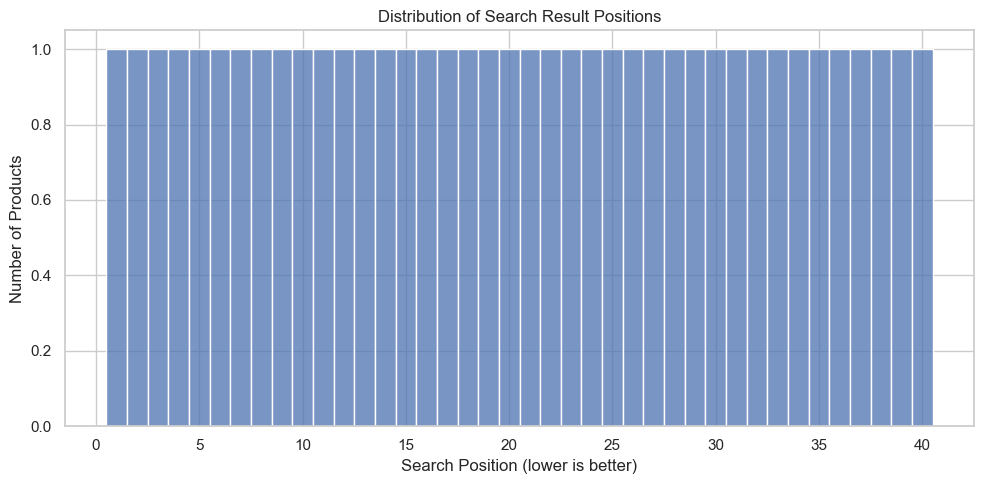

In [22]:
ranked_data = df_eda[
    df_eda["position"].notna()
    & df_eda["visibility_score"].notna()
].copy()

print("Products with search rankings:", len(ranked_data))

if not ranked_data.empty:
    print("\nTop-ranked products:")
    display(
        ranked_data[
            ["title", "platform", "position", "visibility_score"]
        ]
        .sort_values("position")
        .head(10)
    )

    plt.figure(figsize=(10, 5))
    sns.histplot(ranked_data["position"], bins=15, discrete=True)
    plt.title("Distribution of Search Result Positions")
    plt.xlabel("Search Position (lower is better)")
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()
else:
    print("No valid search ranking data is available.")

In [23]:
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

brand_price_summary.to_csv(
    reports_dir / "brand_price_summary.csv"
)

platform_rating_summary.to_csv(
    reports_dir / "platform_rating_summary.csv"
)

if not ranked_data.empty:
    ranked_data.sort_values("position").to_csv(
        reports_dir / "ranked_products.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("EDA analysis files saved successfully!")
print("Folder:", reports_dir)

EDA analysis files saved successfully!
Folder: c:\Users\INDIA\BrandVisibility\reports


In [26]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

# Find the .env file inside the notebooks folder
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    notebook_dir = current_dir
elif (current_dir / "notebooks").is_dir():
    notebook_dir = current_dir / "notebooks"
else:
    notebook_dir = current_dir.parent

env_path = notebook_dir / ".env"
load_dotenv(env_path, override=True)

# Load MySQL settings
host = os.getenv("MYSQL_HOST", "localhost")
port = int(os.getenv("MYSQL_PORT", "3306"))
user = os.getenv("MYSQL_USER", "root")
password = os.getenv("MYSQL_PASSWORD")

if not password:
    raise ValueError(
        "MYSQL_PASSWORD not found. Check your .env file."
    )

# Create the SQLAlchemy engine
engine = create_engine(
    f"mysql+pymysql://{quote_plus(user)}:{quote_plus(password)}"
    f"@{host}:{port}/brand_visibility"
)

# Test the connection
with engine.connect() as connection:
    print("Connected database:", connection.execute(
        text("SELECT DATABASE()")
    ).scalar())

print("MySQL engine created successfully!")

Connected database: brand_visibility
MySQL engine created successfully!


In [27]:
from sqlalchemy import text

with engine.connect() as connection:
    # Check available tables
    tables = connection.execute(
        text("SHOW TABLES")
    ).fetchall()

    print("Tables in brand_visibility database:")
    for table in tables:
        print(table[0])

Tables in brand_visibility database:
products


In [28]:
with engine.connect() as connection:
    count = connection.execute(
        text("SELECT COUNT(*) FROM products")
    ).scalar()

    print("Total products stored:", count)

Total products stored: 1360


In [29]:
from sqlalchemy import text

with engine.connect() as connection:
    tables = connection.execute(
        text("SHOW TABLES")
    ).fetchall()

    print("Available tables:", [t[0] for t in tables])

Available tables: ['products']


In [30]:
query = """
SELECT
    brand,
    COUNT(*) AS total_products,
    ROUND(AVG(rating), 2) AS average_rating,
    ROUND(AVG(price), 2) AS average_price
FROM products
WHERE brand IS NOT NULL
GROUP BY brand
ORDER BY total_products DESC;
"""

with engine.connect() as connection:
    brand_performance = pd.read_sql(
        text(query), connection
    )

display(brand_performance.head(10))

,brand,total_products,average_rating,average_price
0,HP,170,3.87,33299.64
1,LG,168,3.74,28836.18
2,Philips,152,3.81,30129.80
3,Nike,148,3.76,35075.29
4,Boat,142,3.83,44399.65
5,Puma,142,3.82,38515.66
6,Samsung,138,3.65,26495.65
7,Dell,133,3.78,39872.13
8,Sony,127,3.87,33083.43
9,Apple,28,4.28,613.86


In [31]:
query = """
SELECT
    platform,
    COUNT(*) AS total_products,
    ROUND(AVG(rating), 2) AS average_rating,
    ROUND(AVG(price), 2) AS average_price
FROM products
WHERE platform IS NOT NULL
GROUP BY platform
ORDER BY total_products DESC;
"""

with engine.connect() as connection:
    platform_performance = pd.read_sql(
        text(query), connection
    )

display(platform_performance)

,platform,total_products,average_rating,average_price
0,reliance digital,353,3.73,37372.29
1,amazon,337,3.80,37881.87
2,croma,326,3.85,31341.42
3,flipkart,304,3.79,30774.17
4,apple,3,4.03,298.53
5,walmart,3,4.03,432.75
6,best buy,3,4.37,703.32
7,back market,3,4.13,900.78
8,unclaimed baggage,3,NaN,491.66
9,walmart - yywireless,2,3.80,452.54


In [32]:
%pip install streamlit plotly sqlalchemy pymysql python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sqlalchemy import text

with engine.connect() as connection:
    columns = connection.execute(
        text("SHOW COLUMNS FROM products")
    ).fetchall()

    print("Products table columns:")
    for column in columns:
        print(column[0])